# 08 · Multi-class classification

Homework sub-tasks G, H and I: class-index labels, a `k`-neuron output layer, cross-entropy, accuracy, and a confusion matrix. The shapes and dtypes here are **different from the binary case**, and mixing the two up is the most common source of errors.

Dataset: `rice.csv` — four rice varieties, measured grains. The classes are imbalanced (45 % / 30 % / 18 % / 7 %).

---
## Theory in 60 seconds

- Output layer: **`k` neurons** (one per class), no activation. The outputs are **logits** `z`, shape `(batch, k)`.
- **Softmax** turns logits into probabilities: `pₖ = e^{zₖ} / Σⱼ e^{zⱼ}` — all positive, summing to 1.
- **Cross-entropy** for one sample with true class `c`: `−ln p_c` — again "minus the log of the probability given to the right answer".
- `nn.CrossEntropyLoss` = softmax + log + pick the true class + mean, **all inside the loss**. So: the model outputs raw logits, and the label is the **class index**.

| | binary (07) | multi-class (here) |
|---|---|---|
| output shape | `(batch, 1)` | `(batch, k)` |
| label shape | `(batch, 1)` | `(batch,)` |
| label dtype | `float32` | `int64` |
| loss | `BCEWithLogitsLoss` (or Sigmoid + `BCELoss`) | `CrossEntropyLoss` |
| prediction | `z > 0` | `z.argmax(dim=1)` |

- Softmax is monotonic, so `argmax(logits) == argmax(softmax(logits))`: you need softmax only when you want the **probabilities** themselves.

In [1]:
import sys; sys.path.insert(0, "..")
import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from dnd_utils import check, load_rice, RICE_CLASSES

d = load_rice()
X_train, y_train = d["X_train"], d["y_train"]        # (900, 9) float32, (900,) int64 in {0, 1, 2, 3}
X_val, y_val = d["X_val"], d["y_val"]
X_test, y_test = d["X_test"], d["y_test"]
print(X_train.shape, y_train.shape, y_train.dtype, RICE_CLASSES)

(900, 9) (900,) int64 ['arborio', 'basmati', 'jasmine', 'carnaroli']


---
## Exercise 8.1 · Softmax and cross-entropy by hand

Implement with basic tensor operations only (`exp`, `log`, `sum`, `max`, indexing):

- `my_softmax(z)`: `z` has shape `(n, k)`; returns probabilities `(n, k)`. Make it numerically stable by subtracting each row's maximum before the exponential (this does not change the result — why?).
- `my_cross_entropy(z, y)`: `z` logits `(n, k)`, `y` class indices `(n,)`; returns the mean loss.

<details><summary>Hint — picking the true-class probability of every row</summary>

`p[torch.arange(n), y]` takes element `(i, y[i])` for each row `i` → shape `(n,)`. (The same indexing trick as the third one-hot method in notebook 01.)
</details>

In [2]:
def my_softmax(z):
    z = z - z.max(dim=1, keepdim=True).values          # shift per row; e^(z-m) / sum e^(z-m): the factor e^(-m) cancels
    e = torch.exp(z)
    return e / e.sum(dim=1, keepdim=True)              # keepdim -> (n, 1) so the division is row-wise

def my_cross_entropy(z, y):
    p = my_softmax(z)
    p_true = p[torch.arange(z.shape[0]), y]            # (n,): probability assigned to the correct class
    return -torch.log(p_true).mean()

In [3]:
torch.manual_seed(0)
_z = torch.randn(20, 4) * 2
_y = torch.randint(0, 4, (20,))
check("softmax rows sum to 1", lambda: torch.allclose(my_softmax(_z).sum(dim=1), torch.ones(20)))
check("my_softmax == torch.softmax", lambda: torch.allclose(my_softmax(_z), torch.softmax(_z, dim=1), atol=1e-6))
check("stable for huge logits", lambda: torch.allclose(my_softmax(torch.tensor([[1000.0, 999.0]])), torch.tensor([[0.7311, 0.2689]]), atol=1e-3))
check("my_cross_entropy == nn.CrossEntropyLoss", lambda: torch.allclose(my_cross_entropy(_z, _y), nn.CrossEntropyLoss()(_z, _y), atol=1e-5))

✅ softmax rows sum to 1
✅ my_softmax == torch.softmax
✅ stable for huge logits
✅ my_cross_entropy == nn.CrossEntropyLoss


True

**Reason, then verify.** For a 4-class problem, what is the loss of one sample when

- (a) the logits are all equal (an untrained network, roughly),
- (b) the logits are `[3, 0, 0, 0]` and the true class is 0,
- (c) the logits are `[3, 0, 0, 0]` and the true class is 1?

Give each to 2 decimals.

In [4]:
loss_a = float(np.log(4))                               # p = 1/4 for every class  -> ln 4 = 1.39
loss_b = float(-np.log(np.exp(3) / (np.exp(3) + 3)))    # p_true = e^3/(e^3+3) = 0.87 -> 0.14
loss_c = float(-np.log(1 / (np.exp(3) + 3)))            # p_true = 1/(e^3+3) = 0.043  -> 3.14  (= loss_b + 3)

In [5]:
_L = lambda z, y: nn.CrossEntropyLoss()(torch.tensor([z]), torch.tensor([y])).item()
check("(a) ln 4 ≈ 1.39", lambda: abs(loss_a - _L([0., 0., 0., 0.], 2)) < 0.006)
check("(b) ≈ 0.14", lambda: abs(loss_b - _L([3., 0., 0., 0.], 0)) < 0.006)
check("(c) ≈ 3.14", lambda: abs(loss_c - _L([3., 0., 0., 0.], 1)) < 0.006)

✅ (a) ln 4 ≈ 1.39
✅ (b) ≈ 0.14
✅ (c) ≈ 3.14


True

Keep `ln k` in mind as the **sanity value of an untrained k-class network**: `ln 2 = 0.69`, `ln 3 = 1.10`, `ln 4 = 1.39`, `ln 10 = 2.30`.

---
## Exercise 8.2 · Which calls work? (dtype and shape of the labels)

`logits` has shape `(6, 4)`. Predict for each label tensor whether `nn.CrossEntropyLoss()(logits, labels)` runs (`True`) or raises an error (`False`). Then run the check and **read the error messages** — you want to recognise them instantly in the test.

In [6]:
torch.manual_seed(1)
logits = torch.randn(6, 4)
idx = torch.tensor([0, 3, 1, 1, 2, 0])
label_variants = {
    "A  int64, shape (6,)":            idx,
    "B  float32, shape (6,)":          idx.float(),
    "C  int64, shape (6, 1)":          idx[:, None],
    "D  int32, shape (6,)":            idx.to(torch.int32),
    "E  float32 one-hot, shape (6, 4)": torch.eye(4)[idx],
}

In [7]:
works = {
    "A": True,     # the standard form: class indices, int64 ("Long")
    "B": False,    # float 1-D labels: "expected scalar type Long but found Float"
    "C": False,    # (6, 1): "0D or 1D target tensor expected, multi-target not supported"
    "D": False,    # int32 is not accepted either: indices must be int64  -> .long()
    "E": True,     # float targets of shape (n, k) are read as class PROBABILITIES; a one-hot row gives the same loss as A
}

In [8]:
for name, lab in label_variants.items():
    try:
        val = nn.CrossEntropyLoss()(logits, lab).item(); ok = True; msg = f"loss = {val:.4f}"
    except Exception as e:
        ok = False; msg = f"{type(e).__name__}: {str(e)[:90]}"
    check(f"{name:34s} {msg}", lambda: works[name[0]] is ok)

✅ A  int64, shape (6,)               loss = 2.1557
✅ B  float32, shape (6,)             RuntimeError: expected target dtype to be Long or Byte, but got Float
✅ C  int64, shape (6, 1)             RuntimeError: 0D or 1D target tensor expected, multi-target not supported
✅ D  int32, shape (6,)               RuntimeError: expected target dtype to be Long or Byte, but got Int
✅ E  float32 one-hot, shape (6, 4)   loss = 2.1557


---
## Exercise 8.3 · Class distribution and the baseline

Compute `class_counts` (shape `(4,)`) for the training set and `baseline_acc`: the test accuracy of always predicting the training majority class.

In [9]:
class_counts = np.bincount(y_train, minlength=4)
baseline_acc = float((y_test == class_counts.argmax()).mean())
print(class_counts, class_counts / class_counts.sum(), baseline_acc)

[411 261 163  65] [0.45666667 0.29       0.18111111 0.07222222] 0.46


In [10]:
check("class_counts", lambda: list(class_counts) == list(np.bincount(y_train, minlength=4)))
check("baseline_acc", lambda: abs(baseline_acc - (y_test == 0).mean()) < 1e-9)

✅ class_counts
✅ baseline_acc


True

---
## Exercise 8.4 · Dataset, model, training

1. `ClassificationDataset`: inputs `float32`, labels `int64`; batches `(batch, 9)` and `(batch,)`. Three loaders, batch size 32.
2. `RiceMLP`: `9 → 32 → 16 → 4`, ReLU, **no softmax**.
3. Train a fresh model for 60 epochs with `CrossEntropyLoss` and `Adam(lr=0.001)`; record `train_losses`, `val_losses`, `train_accs`, `val_accs` per epoch, and the validation loss of the untrained model in `initial_val_loss`.

In [11]:
class ClassificationDataset(Dataset):
    def __init__(self, x, y):
        self.xs = torch.tensor(x, dtype=torch.float32)
        self.ys = torch.tensor(y, dtype=torch.int64)
    def __len__(self):
        return self.xs.shape[0]
    def __getitem__(self, idx):
        return self.xs[idx], self.ys[idx]              # scalar label -> (batch,)

loader_train = DataLoader(ClassificationDataset(X_train, y_train), batch_size=32, shuffle=True)
loader_val = DataLoader(ClassificationDataset(X_val, y_val), batch_size=32, shuffle=True)
loader_test = DataLoader(ClassificationDataset(X_test, y_test), batch_size=32, shuffle=False)

class RiceMLP(nn.Module):
    def __init__(self, n_inputs, n_classes):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_inputs, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(),
                                    nn.Linear(16, n_classes))          # k logits; softmax lives inside the loss
    def forward(self, x):
        return self.layers(x)

def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    losses, accs = [], []
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            logits = model(xb)                         # (batch, 4)
            loss = loss_fn(logits, yb)                 # yb: (batch,) int64
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            losses.append(loss.item())
            accs.append((logits.argmax(dim=1) == yb).float().mean().item())
    return float(np.mean(losses)), float(np.mean(accs))

torch.manual_seed(0)
model = RiceMLP(X_train.shape[1], 4)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

initial_val_loss, _ = run_epoch(model, loader_val, loss_fn)
train_losses, val_losses, train_accs, val_accs = [], [], [], []
for epoch in range(60):
    tl, ta = run_epoch(model, loader_train, loss_fn, optimizer)
    vl, va = run_epoch(model, loader_val, loss_fn)
    train_losses.append(tl); val_losses.append(vl); train_accs.append(ta); val_accs.append(va)
    if epoch % 10 == 0 or epoch == 59:
        print(f"epoch {epoch:2d}  train loss {tl:.3f} acc {ta:.3f}   val loss {vl:.3f} acc {va:.3f}")
print("initial validation loss:", initial_val_loss, "  ln 4 =", np.log(4))

epoch  0  train loss 1.359 acc 0.403   val loss 1.269 acc 0.706


epoch 10  train loss 0.278 acc 0.895   val loss 0.334 acc 0.847


epoch 20  train loss 0.234 acc 0.918   val loss 0.289 acc 0.876


epoch 30  train loss 0.215 acc 0.917   val loss 0.281 acc 0.884


epoch 40  train loss 0.212 acc 0.921   val loss 0.304 acc 0.877


epoch 50  train loss 0.216 acc 0.919   val loss 0.304 acc 0.873


epoch 59  train loss 0.209 acc 0.912   val loss 0.304 acc 0.871
initial validation loss: 1.4308241605758667   ln 4 = 1.3862943611198906


In [12]:
check("model outputs (batch, 4) logits", lambda: model(torch.randn(5, 9)).shape == (5, 4))
check("no softmax inside the model (outputs are not rows of probabilities)", lambda: not torch.allclose(model(torch.randn(50, 9)).sum(dim=1), torch.ones(50), atol=1e-3))
check("initial loss is close to ln 4 = 1.386", lambda: abs(initial_val_loss - np.log(4)) < 0.15)
check("training loss went down clearly", lambda: train_losses[-1] < 0.6)
check("validation accuracy above the baseline", lambda: val_accs[-1] > baseline_acc + 0.2)

✅ model outputs (batch, 4) logits
✅ no softmax inside the model (outputs are not rows of probabilities)
✅ initial loss is close to ln 4 = 1.386
✅ training loss went down clearly
✅ validation accuracy above the baseline


True

---
## Exercise 8.5 · Test evaluation, and from logits to probabilities

On the full test set compute:

- `test_logits` `(300, 4)`, `test_true` `(300,)`
- `test_ce`, `test_acc`
- `test_pred` `(300,)`: predicted class indices
- `test_probs` `(300, 4)`: class probabilities

In [13]:
model.eval()
ls, ts = [], []
with torch.no_grad():
    for xb, yb in loader_test:
        ls.append(model(xb)); ts.append(yb)
test_logits, test_true = torch.cat(ls), torch.cat(ts)

test_ce = loss_fn(test_logits, test_true).item()
test_pred = test_logits.argmax(dim=1)                       # no softmax needed for the decision
test_acc = (test_pred == test_true).float().mean().item()
test_probs = torch.softmax(test_logits, dim=1)              # softmax only when the probabilities themselves are wanted
print(f"test CE {test_ce:.3f}   accuracy {test_acc:.3f}   baseline {baseline_acc:.3f}")
for i in range(5):
    print(f"true {RICE_CLASSES[test_true[i]]:10s} predicted {RICE_CLASSES[test_pred[i]]:10s} probabilities {np.round(test_probs[i].numpy(), 2)}")

test CE 0.257   accuracy 0.897   baseline 0.460
true jasmine    predicted jasmine    probabilities [0.   0.26 0.74 0.  ]
true arborio    predicted arborio    probabilities [0.99 0.   0.   0.01]
true arborio    predicted arborio    probabilities [0.85 0.   0.   0.15]
true basmati    predicted jasmine    probabilities [0.   0.09 0.91 0.  ]
true basmati    predicted basmati    probabilities [0. 1. 0. 0.]


In [14]:
check("shapes", lambda: test_logits.shape == (300, 4) and test_true.shape == (300,) and test_pred.shape == (300,) and test_probs.shape == (300, 4))
check("probabilities sum to 1 per row", lambda: torch.allclose(test_probs.sum(dim=1), torch.ones(300), atol=1e-5))
check("argmax of probabilities == argmax of logits", lambda: torch.equal(test_probs.argmax(dim=1), test_pred))
check("test accuracy well above the baseline", lambda: test_acc > baseline_acc + 0.2)

✅ shapes
✅ probabilities sum to 1 per row
✅ argmax of probabilities == argmax of logits
✅ test accuracy well above the baseline


True

---
## Exercise 8.6 · The confusion matrix

`cm[i, j]` = number of samples whose **true** class is `i` and **predicted** class is `j`.

Write `confusion_matrix(y_true, y_pred, k)` for NumPy integer arrays — **without a Python loop over the samples**.

<details><summary>Hint 1 — the bincount trick</summary>

Each (true, predicted) pair can be encoded as one integer `true * k + pred` between 0 and k²−1. Count them with `np.bincount(..., minlength=k * k)` and reshape to `(k, k)`.
</details>
<details><summary>Hint 2 — the alternative</summary>

`cm = np.zeros((k, k), dtype=int); np.add.at(cm, (y_true, y_pred), 1)` — adds 1 at every (row, column) pair, correctly handling repeated pairs (plain `cm[y_true, y_pred] += 1` does **not**).
</details>

In [15]:
def confusion_matrix(y_true, y_pred, k):
    return np.bincount(y_true * k + y_pred, minlength=k * k).reshape(k, k)

cm = confusion_matrix(test_true.numpy(), test_pred.numpy(), 4)
print(cm)

[[132   0   1   5]
 [  0  89   8   0]
 [  2   9  39   0]
 [  6   0   0   9]]


In [16]:
_t = np.array([0, 0, 1, 2, 2, 2, 3]); _p = np.array([0, 1, 1, 2, 0, 2, 2])
check("small example", lambda: confusion_matrix(_t, _p, 4).tolist() == [[1, 1, 0, 0], [0, 1, 0, 0], [1, 0, 2, 0], [0, 0, 1, 0]])
check("cm sums to the number of test samples", lambda: cm.shape == (4, 4) and cm.sum() == 300)
check("row sums = number of true samples per class", lambda: (cm.sum(axis=1) == np.bincount(y_test, minlength=4)).all())
check("trace / total = accuracy", lambda: abs(np.trace(cm) / cm.sum() - test_acc) < 1e-6)

✅ small example
✅ cm sums to the number of test samples
✅ row sums = number of true samples per class
✅ trace / total = accuracy


True

Plot it with `plt.imshow`. Requirements (as in the homework): it must be visible which axis is *true* and which is *predicted*, the class names at the ticks, and the count written inside every cell. A small loop over the `k × k` cells for the text is fine.

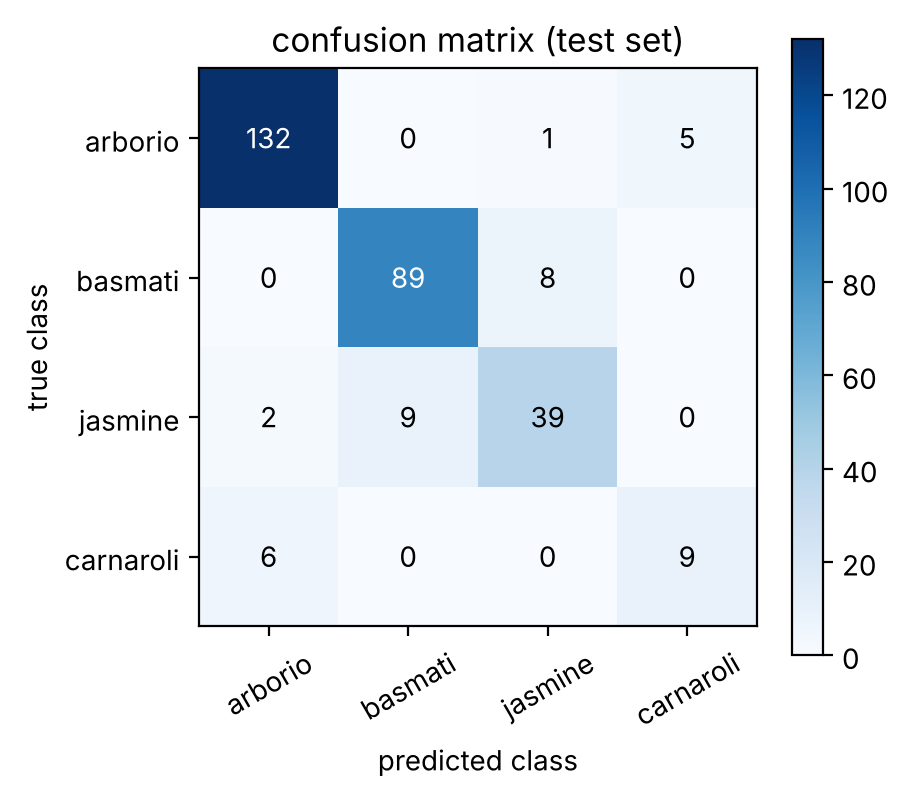

In [17]:
plt.figure(figsize=(4.5, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xlabel("predicted class")                 # columns = second index = predicted
plt.ylabel("true class")                      # rows = first index = true
plt.xticks(range(4), RICE_CLASSES, rotation=30)
plt.yticks(range(4), RICE_CLASSES)
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")   # x = column j, y = row i
plt.title("confusion matrix (test set)")
plt.show()

---
## Exercise 8.7 · Per-class precision, recall, F1 — from the matrix

Vectorised, from `cm` alone: `precision`, `recall`, `f1` as arrays of shape `(4,)`, and `macro_f1` (the plain average of the four F1 values). Where a denominator is 0, the metric must be 0 (no `nan`, no warning).

Which **axis** of `cm` do you sum over for precision, and which for recall? Work it out from the definition of `cm[i, j]` before coding.

In [18]:
def per_class_metrics(cm):
    """returns precision, recall, f1 -- each of shape (k,)"""
    tp = np.diag(cm).astype(float)                 # correct predictions of each class
    predicted = cm.sum(axis=0)                     # column sums: how often each class was PREDICTED  (TP + FP)
    actual = cm.sum(axis=1)                        # row sums: how often each class really OCCURS      (TP + FN)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, actual, out=np.zeros_like(tp), where=actual > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    return precision, recall, f1

precision, recall, f1 = per_class_metrics(cm)
macro_f1 = float(f1.mean())
for c in range(4):
    print(f"{RICE_CLASSES[c]:10s} precision {precision[c]:.3f}  recall {recall[c]:.3f}  F1 {f1[c]:.3f}   ({cm[c].sum()} test samples)")
print(f"accuracy {test_acc:.3f}   macro-F1 {macro_f1:.3f}")

arborio    precision 0.943  recall 0.957  F1 0.950   (138 test samples)
basmati    precision 0.908  recall 0.918  F1 0.913   (97 test samples)
jasmine    precision 0.812  recall 0.780  F1 0.796   (50 test samples)
carnaroli  precision 0.643  recall 0.600  F1 0.621   (15 test samples)
accuracy 0.897   macro-F1 0.820


In [19]:
_cm = np.array([[8, 2, 0], [1, 5, 0], [3, 1, 0]])       # class 2 is never predicted
check("small example: precision", lambda: np.allclose(per_class_metrics(_cm)[0], [8 / 12, 5 / 8, 0.0]))
check("small example: recall", lambda: np.allclose(per_class_metrics(_cm)[1], [0.8, 5 / 6, 0.0]))
check("small example: f1 (0 for the never-predicted class, no nan)", lambda: np.allclose(per_class_metrics(_cm)[2], [2 * 8 / (2 * 8 + 4 + 2), 2 * 5 / (2 * 5 + 3 + 1), 0.0]))
check("test set: recall = diagonal / row sums", lambda: np.allclose(recall, np.diag(cm) / cm.sum(axis=1)))
check("macro_f1", lambda: abs(macro_f1 - np.mean(f1)) < 1e-9)

✅ small example: precision
✅ small example: recall
✅ small example: f1 (0 for the never-predicted class, no nan)
✅ test set: recall = diagonal / row sums
✅ macro_f1


True

Look at the row of the rarest class (carnaroli). Accuracy barely notices it — why? Which single number in your output would you report to show how well the model treats **all** classes?

**Answer.** Accuracy weights every *sample* equally, so a class that makes up 7 % of the data can contribute at most 7 points: a model that gets every carnaroli grain wrong could still reach 93 %. Per-class recall (the diagonal divided by the row sums) exposes it. A single summarising number that treats all *classes* equally is the **macro-averaged F1** (or macro recall, also called balanced accuracy): each class counts the same regardless of its size.

---
## Exercise 8.8 · Class weights in `CrossEntropyLoss`

`nn.CrossEntropyLoss(weight=w)` with `w` of shape `(k,)` multiplies the loss of each sample by the weight of **its true class**. Its `mean` reduction is a *weighted* mean:

$$L = \frac{\sum_i w_{y_i}\,\ell_i}{\sum_i w_{y_i}}$$

**a)** Reproduce it by hand with `reduction="none"`.

In [20]:
def weighted_ce(logits, y, w):
    """logits (n, k), y (n,) int64, w (k,) float tensor -> scalar"""
    per_sample = nn.CrossEntropyLoss(reduction="none")(logits, y)     # (n,)
    sample_w = w[y]                                                   # (n,): integer indexing looks up each sample's class weight
    return (per_sample * sample_w).sum() / sample_w.sum()

In [21]:
_w = torch.tensor([1.0, 2.0, 0.5, 4.0])
check("equals nn.CrossEntropyLoss(weight=w)", lambda: torch.allclose(weighted_ce(_z, _y, _w), nn.CrossEntropyLoss(weight=_w)(_z, _y), atol=1e-6))
check("all weights 1 -> ordinary cross-entropy", lambda: torch.allclose(weighted_ce(_z, _y, torch.ones(4)), nn.CrossEntropyLoss()(_z, _y), atol=1e-6))

✅ equals nn.CrossEntropyLoss(weight=w)
✅ all weights 1 -> ordinary cross-entropy


True

**b)** Compute "inverse-frequency" weights `class_w = n / (k · count_c)` from the training set (so a class that is half as frequent gets double the weight; a perfectly balanced set would give all ones). Train a fresh `RiceMLP` exactly as before but with the weighted loss, then compute its per-class recall on the test set as `recall_w` (shape `(4,)`) and its accuracy `acc_w`.

In [22]:
class_w = torch.tensor(len(y_train) / (4 * class_counts), dtype=torch.float32)
print("class weights:", class_w)

torch.manual_seed(0)
model_w = RiceMLP(X_train.shape[1], 4)
loss_w = nn.CrossEntropyLoss(weight=class_w)
opt_w = torch.optim.Adam(model_w.parameters(), lr=0.001)
for epoch in range(60):
    run_epoch(model_w, loader_train, loss_w, opt_w)

model_w.eval()
with torch.no_grad():
    pred_w = model_w(torch.tensor(X_test)).argmax(dim=1).numpy()
cm_w = confusion_matrix(y_test, pred_w, 4)
recall_w = per_class_metrics(cm_w)[1]
acc_w = float((pred_w == y_test).mean())
print("recall plain   :", np.round(recall, 3), " accuracy %.3f  macro-F1 %.3f" % (test_acc, macro_f1))
print("recall weighted:", np.round(recall_w, 3), " accuracy %.3f  macro-F1 %.3f" % (acc_w, per_class_metrics(cm_w)[2].mean()))

class weights: tensor([0.5474, 0.8621, 1.3804, 3.4615])


recall plain   : [0.957 0.918 0.78  0.6  ]  accuracy 0.897  macro-F1 0.820
recall weighted: [0.848 0.907 0.8   0.867]  accuracy 0.860  macro-F1 0.791


In [23]:
check("class_w = n / (k * count)", lambda: torch.allclose(class_w, torch.tensor(900 / (4 * np.bincount(y_train, minlength=4)), dtype=torch.float32)))
check("the rarest class has the largest weight", lambda: class_w.argmax().item() == 3)
check("recall of the rarest class did not get worse", lambda: recall_w[3] >= recall[3] - 0.05)
check("still far above the baseline", lambda: acc_w > baseline_acc + 0.2)

✅ class_w = n / (k * count)
✅ the rarest class has the largest weight
✅ recall of the rarest class did not get worse
✅ still far above the baseline


True

---
## Exercise 8.9 · Bug hunt: softmax inside the model

A very common mistake: adding `nn.Softmax(dim=1)` as the last layer **and** using `nn.CrossEntropyLoss`. No error, no warning.

**a)** The loss now receives a probability vector (entries in `[0, 1]`, summing to 1) and treats it as logits. For 4 classes, what is the lowest loss a single sample can reach? (The best the model can do is output exactly `[1, 0, 0, 0]` for a class-0 sample.)

In [24]:
floor_4_classes = float(-np.log(np.exp(1) / (np.exp(1) + 3)))       # "logits" (1,0,0,0) -> p_true = e/(e+3) = 0.475 -> 0.744

In [25]:
check("floor ≈ 0.744", lambda: abs(floor_4_classes - 0.7437) < 1e-3)

✅ floor ≈ 0.744


True

**b)** Run both trainings below (identical except for the extra softmax) and compare.

In [26]:
class RiceMLPBuggy(nn.Module):
    def __init__(self, n_inputs, n_classes):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_inputs, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(),
                                    nn.Linear(16, n_classes), nn.Softmax(dim=1))       # <- the bug
    def forward(self, x):
        return self.layers(x)

try:
    for cls in (RiceMLP, RiceMLPBuggy):
        torch.manual_seed(0)
        m = cls(9, 4); o = torch.optim.Adam(m.parameters(), lr=0.001); hist = []
        for epoch in range(60):
            hist.append(run_epoch(m, loader_train, nn.CrossEntropyLoss(), o)[0])
        vl, va = run_epoch(m, loader_val, nn.CrossEntropyLoss())
        print(f"{cls.__name__:13s} training loss after 1 / 10 / 60 epochs: {hist[0]:.3f} / {hist[9]:.3f} / {hist[-1]:.3f}    validation accuracy {va:.3f}")
except NameError as e:
    print("finish exercise 8.4 first:", e)

RiceMLP       training loss after 1 / 10 / 60 epochs: 1.352 / 0.319 / 0.214    validation accuracy 0.887


RiceMLPBuggy  training loss after 1 / 10 / 60 epochs: 1.376 / 0.893 / 0.857    validation accuracy 0.836


The buggy model's accuracy is not catastrophic — so how would you *notice* this bug in the test, from the numbers alone? And why does it train more slowly?

**Answer.** Fingerprints: (1) the loss **cannot go below ≈ 0.74** (for 4 classes; `−ln(e/(e+k−1))` in general) however long you train, and it starts *at* about `ln 4` and moves slowly; (2) the "initial loss ≈ ln k" check still passes, so only the floor gives it away; (3) if you print the model's outputs, the rows sum to 1 — logits never do that. It trains slowly because the outputs are squeezed into `[0, 1]`: the loss sees "logits" that can differ by at most 1, so its gradient signal is weak, and it is passed through the softmax derivative as well (which is small when the softmax saturates). The argmax is unaffected, so accuracy can still be decent — which is exactly why the bug survives unnoticed.

---
## Blank-page drill

New empty notebook, 30 minutes. From `d = load_rice()`:

1. dataset (correct label dtype!) and loaders;
2. model `9 → 30 → 20 → 4`;
3. training loop with loss and accuracy on training and validation data, 60 epochs;
4. plot of the curves with legend;
5. test cross-entropy and accuracy on the full test set;
6. 8 example predictions next to the true classes;
7. confusion matrix computed in NumPy and plotted with labelled axes and counts in the cells.

Afterwards, check yourself against the table at the top of this notebook: output shape, label shape, label dtype, loss, prediction rule — could you fill it in for *both* columns from memory?

In [27]:
# Every piece of this drill appears above: ClassificationDataset, RiceMLP, run_epoch (or the inline loop from
# notebook 06), the evaluation in 8.5, confusion_matrix in 8.6 and the imshow plot.
print("see exercises 8.4 - 8.6 of this solution notebook")

see exercises 8.4 - 8.6 of this solution notebook
